# Digital Image Processing (DIP) - Section 3
## Spatial Domain Transformations: Brightness, Contrast Stretching, Gamma Correction & Histogram Equalization

### 🎯 Learning Objectives
1. **Point Processing Transfer Functions:** Understand spatial domain mapping $s = T(r)$ where each output pixel depends solely on its corresponding input pixel.
2. **Brightness Adjustment:** Implement linear offsets using both vectorized array operations and nested pixel-by-pixel loops with $[0, 255]$ saturation clamping.
3. **Contrast Stretching (Min-Max Normalization):** Expand dynamic range across color channels from an arbitrary sub-interval $[r_{\min}, r_{\max}]$ to the full spectrum $[0, 255]$.
4. **Gamma Correction (Power-Law Transformation):** Apply non-linear tone mapping $s = c \cdot r^\gamma$ to adjust shadow and highlight perception.
5. **Histogram Equalization:** Compute image histograms, cumulative distribution functions (CDF), generate a Lookup Table (LUT), and uniformly redistribute intensity levels.


---
## 1. Brightness Adjustment (Linear Offset: Vectorized vs. Manual Loop)

### 🎯 Objective & Purpose
- **Goal:** Increase or decrease overall image luminosity to reveal hidden details in underexposed (dark) scenes or tone down overexposed areas.
- **Why?** Poor lighting is a ubiquitous real-world acquisition problem; brightness adjustment is the foundational spatial-domain point-processing operation in computer vision.

### ⚙️ Underlying Algorithm: Spatial Domain Point Processing
In **Point Processing**, the output intensity $s(x, y)$ depends **solely** on the input intensity $r(x, y)$ at the exact same spatial coordinates, independent of neighbor pixels:
$$s(x, y) = T\big(r(x, y)\big) = r(x, y) + \text{bias}$$

- **Histogram Translation:** Adding a positive scalar $\text{bias} > 0$ shifts the entire histogram to the right (brightening), while $\text{bias} < 0$ shifts it to the left (darkening).

### ⚠️ Critical Problem Solved: The `uint8` Overflow / Wrap-Around ($250 + 50 = 44$)
In standard 8-bit digital imaging (`uint8`), values are restricted to $[0, 255]$ ($2^8 = 256$ levels):
- **Modulo Wrap-Around:** If we perform native `uint8` addition without casting:
  $$250 + 50 = 300 \implies 300 \pmod{256} = \mathbf{44}$$
  *(A bright sky highlight at 250 wraps around and turns into a dark spot at 44!)*
- **Clamping / Saturation Solution:**
  To eliminate this destructive overflow artifact, pixel values are first cast to a higher bit-depth (`int32`), added to the bias, and then **clamped (clipped)** to $[0, 255]$ before converting back to `uint8`:
  $$\text{clamp}(v, 0, 255) = \min\big(\max(v, 0), 255\big) = \begin{cases} 0 & \text{if } v < 0 \\ 255 & \text{if } v > 255 \\ v & \text{otherwise} \end{cases}$$

### 💻 Implementation Strategies Demonstrated Below:
1. **Method 1: Vectorized Array Math (`NumPy`):**
   Leverages contiguous C-level memory structures and SIMD vector instructions (`arr.astype(np.int32) + bias` $\rightarrow$ `np.clip(...)`). Runs in milliseconds for high-resolution images.
2. **Method 2: Explicit Pixel-by-Pixel Loops (`3D Nested Loop`):**
   Iterates through every row $H$, column $W$, and color channel $C$ with manual `if-elif` boundary checks. Excellent for pedagogical understanding of spatial matrix traversal.


Image shape: (359, 496, 3)


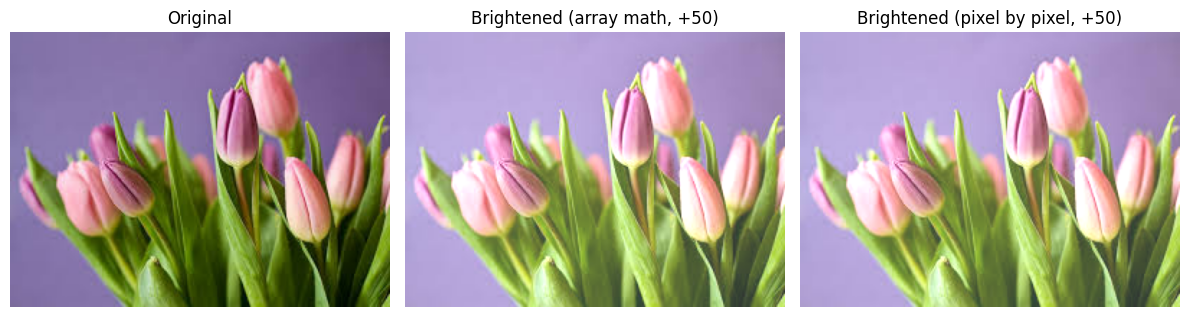

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# ---------- Load image ----------
img = Image.open("image.png").convert("RGB")
arr = np.array(img)   # shape (H, W, 3)
H, W, C = arr.shape
print("Image shape:", arr.shape)

# ---------- Method 1: vectorized (array math) ----------
# Brightness factor
bias = 50
bright_arr = arr.astype(np.int32) + bias
bright_arr = np.clip(bright_arr, 0, 255).astype(np.uint8)

# ---------- Method 2: pixel-by-pixel loop (manual way) ----------
bright_manual = np.zeros_like(arr, dtype=np.uint8)

for i in range(H):
    for j in range(W):
        for k in range(C):
            new_val = int(arr[i, j, k]) + bias
            # clamp 0–255
            if new_val > 255:
                new_val = 255
            elif new_val < 0:
                new_val = 0
            bright_manual[i, j, k] = new_val

# ---------- Display ----------
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.imshow(arr)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright_arr)
plt.title(f"Brightened (array math, +{bias})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(bright_manual)
plt.title(f"Brightened (pixel by pixel, +{bias})")
plt.axis("off")

plt.tight_layout()
plt.show()


---
## 2. Contrast Stretching (Min-Max Normalization)

### 📘 Theoretical Description:
- **The Problem of Low Dynamic Range:**
  Images captured in low-light, foggy, or backlit conditions often utilize only a fraction of the available $0–255$ gray levels. A photo with values restricted between $r_{\min} = 60$ and $r_{\max} = 170$ appears washed-out, dull, and lacks clear distinction between subtle details.
- **Linear Stretch Equation:**
  Contrast stretching linearly scales the interval $[r_{\min}, r_{\max}]$ across the entire available dynamic range $[0, 255]$:
  $$s = \frac{r - r_{\min}}{r_{\max} - r_{\min}} \times 255.0$$
- **Channel Independence in RGB:**
  Applying min-max stretching to each RGB channel independently ($c \in \{0, 1, 2\}$) maximizes dynamic range across Red, Green, and Blue spectra, enhancing color vibrancy and contrast simultaneously.
- **Zero-Division Safeguard:**
  If an image channel is flat/constant ($r_{\max} == r_{\min}$), division by zero is avoided by leaving the channel unchanged.


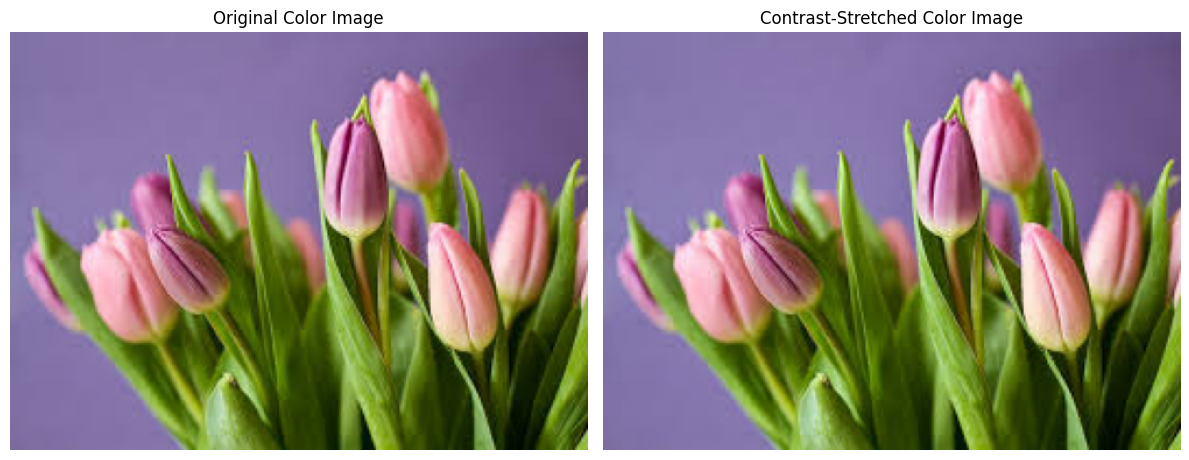

In [2]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load the colored image
image = Image.open("image.png").convert("RGB")
img = np.array(image)

# 2. Apply contrast stretching to each RGB channel
stretched = np.zeros_like(img)

for c in range(3):
    channel = img[:, :, c].astype(np.float32)

    r_min = np.min(channel)
    r_max = np.max(channel)

    if r_max > r_min:
        stretched[:, :, c] = np.clip((channel - r_min) * 255.0 / (r_max - r_min), 0, 255).astype(np.uint8)
    else:
        stretched[:, :, c] = channel.astype(np.uint8)

# 3. Display original and enhanced images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched)
plt.title("Contrast-Stretched Color Image")
plt.axis("off")

plt.tight_layout()
plt.show()


---
## 3 & 4. Gamma Correction (Power-Law Transformation)

### 📘 Theoretical Description:
- **Power-Law Transformation Formula:**
  $$s = c \cdot r^\gamma$$
  where $c$ is a scaling constant (typically $1$) and $\gamma$ (gamma) controls the curve curvature.
- **Why Normalization to $[0.0, 1.0]$ is Essential:**
  Pixel values must be normalized to $[0, 1]$ before exponentiation:
  $$r_{\text{norm}} = \frac{r}{255.0}, \quad s_{\text{norm}} = r_{\text{norm}}^\gamma, \quad s = s_{\text{norm}} \times 255.0$$
  Without normalization, raising 8-bit integers directly ($200^{0.5} \approx 14.14$) would drastically crush image intensities!
- **Behavior of Gamma Values:**
  - $\gamma < 1$ (e.g. $\gamma = 0.5$): **Brightens the image**. Dark shadows and underexposed regions are stretched upward into midtones, revealing hidden details without blowing out pure white.
  - $\gamma = 1$: **Linear identity mapping** ($s = r$).
  - $\gamma > 1$ (e.g. $\gamma = 2.2$): **Darkens the image**. Compresses dark values and expands highlights (used in display gamma calibration).


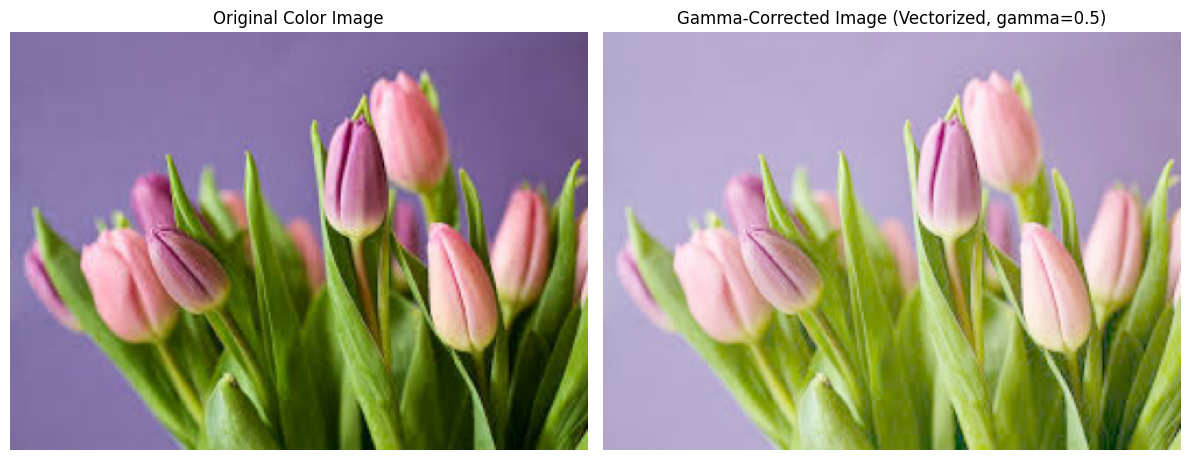

In [3]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load the colored image
image = Image.open("image.png").convert("RGB")
img = np.array(image)

# 2. Set the gamma value
gamma = 0.5

# 3. Normalize pixel values to [0, 1]
normalized = img.astype(np.float32) / 255.0

# 4. Apply gamma correction to all RGB channels
corrected = np.power(normalized, gamma)

# 5. Convert values back to [0, 255]
corrected = np.clip(corrected * 255.0, 0, 255).astype(np.uint8)

# 6. Display original and corrected images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corrected)
plt.title(f"Gamma-Corrected Image (Vectorized, gamma={gamma})")
plt.axis("off")

plt.tight_layout()
plt.show()


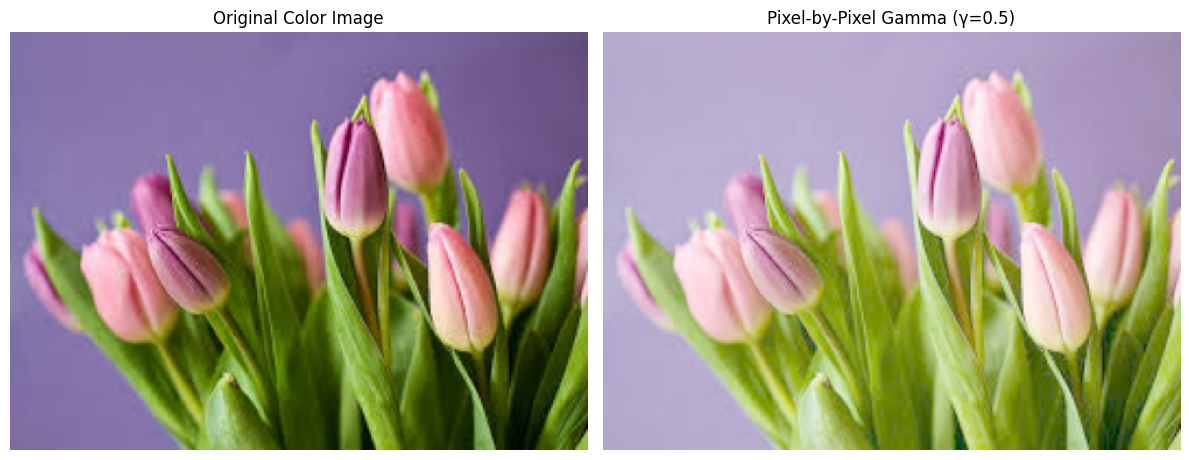

In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load the color image
image = Image.open("image.png").convert("RGB")
img = np.array(image)

# Get image dimensions
height, width, channels = img.shape

# 2. Set gamma
gamma = 0.5

# Create output image
corrected_pixel = np.zeros_like(img)

# 3. Apply gamma correction pixel by pixel
for i in range(height):
    for j in range(width):
        for c in range(3):
            pixel = img[i, j, c] / 255.0

            value = pixel ** gamma

            corrected_pixel[i, j, c] = int(
                np.clip(value * 255.0, 0, 255)
            )

# 4. Display original and corrected images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corrected_pixel)
plt.title(f"Pixel-by-Pixel Gamma (γ={gamma})")
plt.axis("off")

plt.tight_layout()
plt.show()


---
## 5. Histogram Equalization (Grayscale CDF & LUT Mapping)

### 📘 Theoretical Description:
- **What is an Image Histogram?**
  A discrete frequency distribution showing the number of pixels $n_k$ having gray level $r_k$:
  $$p(r_k) = \frac{n_k}{M \times N}, \quad k = 0, 1, \dots, 255$$
- **Cumulative Distribution Function (CDF):**
  The cumulative sum of the histogram represents the probability that a pixel has intensity $\le k$:
  $$CDF(k) = \sum_{j=0}^{k} h(j)$$
- **The Equalization Transfer Function:**
  Histogram equalization creates a monotonic mapping $s_k = T(r_k)$ such that the output image approaches a uniform distribution:
  $$LUT(k) = \text{round}\left( \frac{CDF(k) - CDF_{\min}}{\text{Total Pixels} - CDF_{\min}} \times 255.0 \right)$$
  - **Subtracting $CDF_{\min}$:** Anchors the lowest populated intensity in the input image directly to $0$ (pure black).
  - **Denominator $(\text{Total Pixels} - CDF_{\min})$:** Normalizes the cumulative range to $[0.0, 1.0]$ before scaling to $255$.
- **Lookup Table (LUT) Performance:**
  Building the 256-element LUT requires only $O(256)$ time. Applying it to the image matrix `lut[img]` is an $O(1)$ constant-time memory indexing operation per pixel!


Saved equalized image to 'histogram_equalized_gray.jpg'


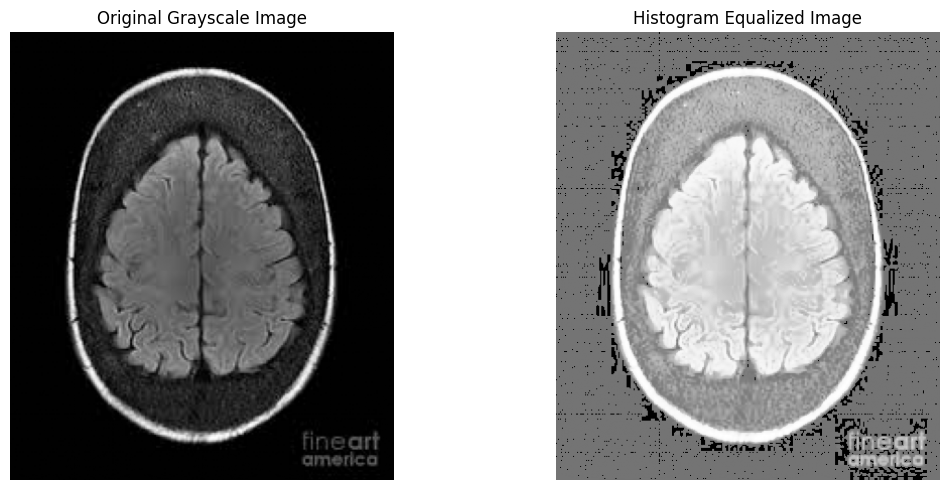

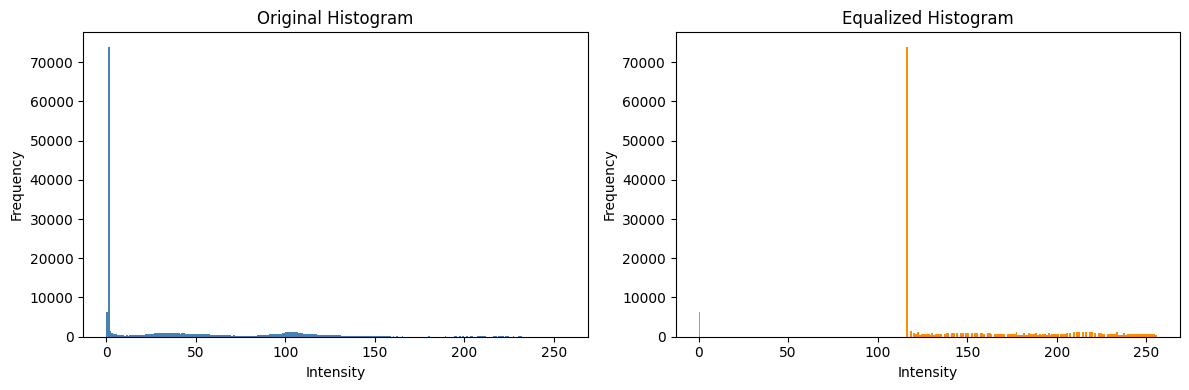

In [5]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load the image in grayscale (using histogramImage.png)
image = Image.open("histogramImage.png").convert("L")
img_gray = np.array(image)

# 2. Calculate the histogram
hist = np.bincount(img_gray.ravel(), minlength=256)

# 3. Calculate the cumulative distribution function (CDF)
cdf = hist.cumsum()

# 4. Find the first nonzero CDF value
cdf_min = cdf[cdf > 0].min()
total_pixels = img_gray.size

# 5. Create the equalization lookup table
if total_pixels > cdf_min:
    lut = np.round(
        (cdf - cdf_min) * 255.0 / (total_pixels - cdf_min)
    )
    lut = np.clip(lut, 0, 255).astype(np.uint8)
else:
    lut = np.arange(256, dtype=np.uint8)

# 6. Apply histogram equalization
equalized = lut[img_gray]

# 7. Display original and equalized images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# 8. Display histograms
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(img_gray.ravel(), bins=256, range=(0, 256), color="steelblue", edgecolor="none")
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(equalized.ravel(), bins=256, range=(0, 256), color="darkorange", edgecolor="none")
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# 9. Save the equalized image
Image.fromarray(equalized).save("histogram_equalized_gray.jpg")
print("Saved equalized image to 'histogram_equalized_gray.jpg'")


---
## 6. Comprehensive Visual Comparison
Comparing all four enhancement techniques side-by-side:
1. **Original RGB Image:** Unaltered input image.
2. **Brightened:** Shifts distribution upward; prone to saturation if bias is too high.
3. **Contrast-Stretched:** Expands narrow dynamic range across full $[0, 255]$ spectrum.
4. **Gamma-Corrected ($\gamma=0.5$):** Non-linearly illuminates shadows while gracefully preserving bright highlights.
5. **Histogram Equalization:** Global redistribution of grayscale intensity frequencies into a flattened, high-contrast spectrum.


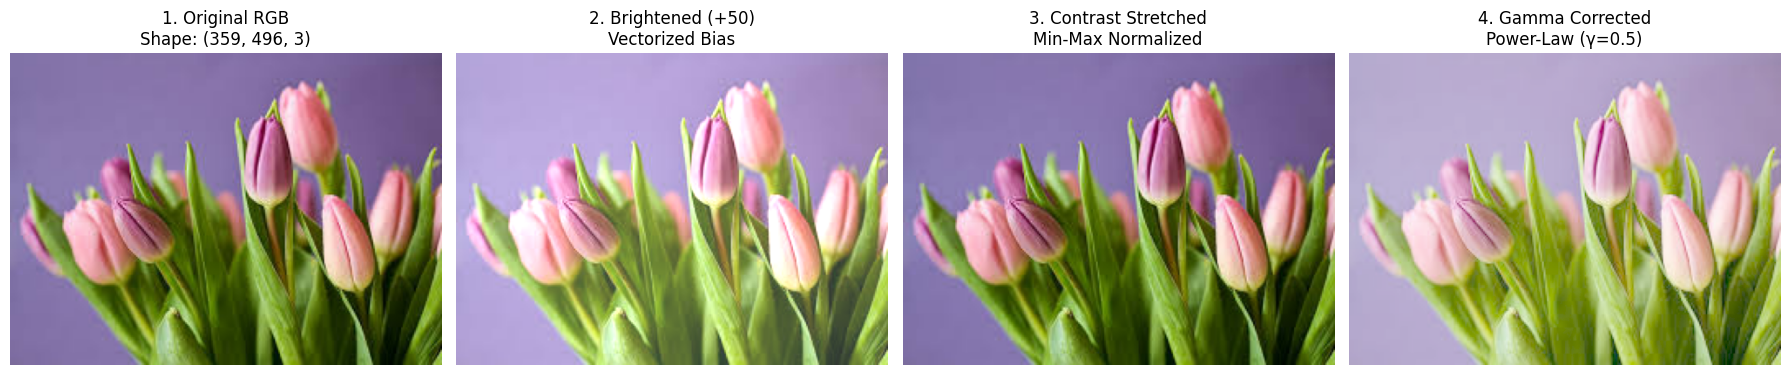

In [6]:
# Visual comparison of the spatial domain techniques
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(arr)
axes[0].set_title(f"1. Original RGB\nShape: {arr.shape}")
axes[0].axis("off")

axes[1].imshow(bright_arr)
axes[1].set_title(f"2. Brightened (+{bias})\nVectorized Bias")
axes[1].axis("off")

axes[2].imshow(stretched)
axes[2].set_title(f"3. Contrast Stretched\nMin-Max Normalized")
axes[2].axis("off")

axes[3].imshow(corrected)
axes[3].set_title(f"4. Gamma Corrected\nPower-Law (γ={gamma})")
axes[3].axis("off")

plt.tight_layout()
plt.show()
